# Phase 2 write-up: light-curve features, CNN, operating points and the sealed test (10/30/2026)

Phase 2 asked one question: **do the Kepler light curves, measured by us, make the catalog classifier better?**
This notebook covers M3–M6 (M0–M2, the download, views and QA, are in `exo101926` and `exo102426`):

1. **M3, Phase 2a:** 11 hand-made light-curve features (+ 2 centroid features), and what they look like per class.
2. **M3 CV:** Phase 1 vs Phase 2a on identical star-grouped folds (5 fold shuffles × 10 seeds, paired star bootstrap).
3. **Blind spots:** which false-positive types got easier, and which are still hard.
4. **M4, Phase 2b:** an AstroNet-style CNN on the views. Tried, not used.
5. **M5:** calibration and the operating-point menu (98% planet recall = headline).
6. **M6:** the one-time sealed-test scoring of the frozen Phase 2 models.

Everything here **reads saved results**: CV out-of-fold predictions, `sweeps/results/p2_*.csv` and the saved test
predictions. Nothing is retrained and the test set is not re-scored. Everything that uses labels before section 6
uses the **CV pool only**. Labels and robovetter flags only group KOIs; they are never model inputs.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
pool0, _ = cv_pool(clean_koi(df_raw))          # the test split is not used before section 6
pool = add_centroid_features(pool0, df_raw)
pool = leftjoin(pool, CSV.read(joinpath(CV_DIR, "p2_lcfeatures.csv"), DataFrame); on = :kepoi_name, order = :left)
@assert pool.kepoi_name == pool0.kepoi_name
for c in [LC_FEATURES; LC_CENTROID_FEATURES]
    pool[!, c] = Float64.(coalesce.(pool[!, c], NaN))
end
y = Float64.(pool.label)
dr = is_dr25(pool, df_raw)
fpat = with_vetting_info(pool, df_raw, zeros(nrow(pool))).flag_pattern
@printf("pool: %d KOIs on %d stars (%d DR25, %d supplemental); planets %d, FPs %d\n", nrow(pool),
        length(unique(pool.kepid)), sum(dr), sum(.!dr), sum(y .== 1), sum(y .== 0))

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
pool: 8288 KOIs on 7135 stars (7199 DR25, 1089 supplemental); planets 4163, FPs 4125


## 1. The Phase 2a light-curve features (M3)

Computed by `src/LCFeatures.jl` from our own detrended light curves (`src/Detrend.jl`), independently of
the robovetter. M2 showed that raw view values are noise-dominated, so each signal is a **significance** against an
empirical noise level: the scatter of one-duration box means away from the transit (which includes red noise on
the transit timescale).

| Feature | Meaning |
|---|---|
| `lc_snr` | our transit depth / box noise: the signal that survives our detrending |
| `lc_depth_ratio` | trapezoid-fit depth / catalog depth |
| `lc_vshape` | trapezoid ingress fraction: 0 = box (planet-like), 1 = V (EB-like) |
| `lc_dur_ratio` | trapezoid duration / catalog duration |
| `lc_oe_sig` | odd vs even depth difference [σ] |
| `lc_sec_sig`, `lc_sec_ratio`, `lc_sec_phase` | deepest off-transit dip (secondary eclipse): significance, depth / primary, phase |
| `lc_sev_ratio` | strongest single transit's SNR / total SNR (≈ 1/√N for N equal transits, ≈ 1 for one glitch) |
| `lc_timing` | robust scatter of per-transit centre offsets [durations] |
| `lc_ntransits` | observed transits |
| `lc_cen_sig`, `lc_cen_offset` | "+ centroid" family only: in-transit centroid shift [σ] and shift / depth [pixels] |

Distributions per class on the pool (cumulative distributions, so every KOI counts once and nothing is binned).
FP classes are "pure" (one robovetter flag only), as in M0 and M2.

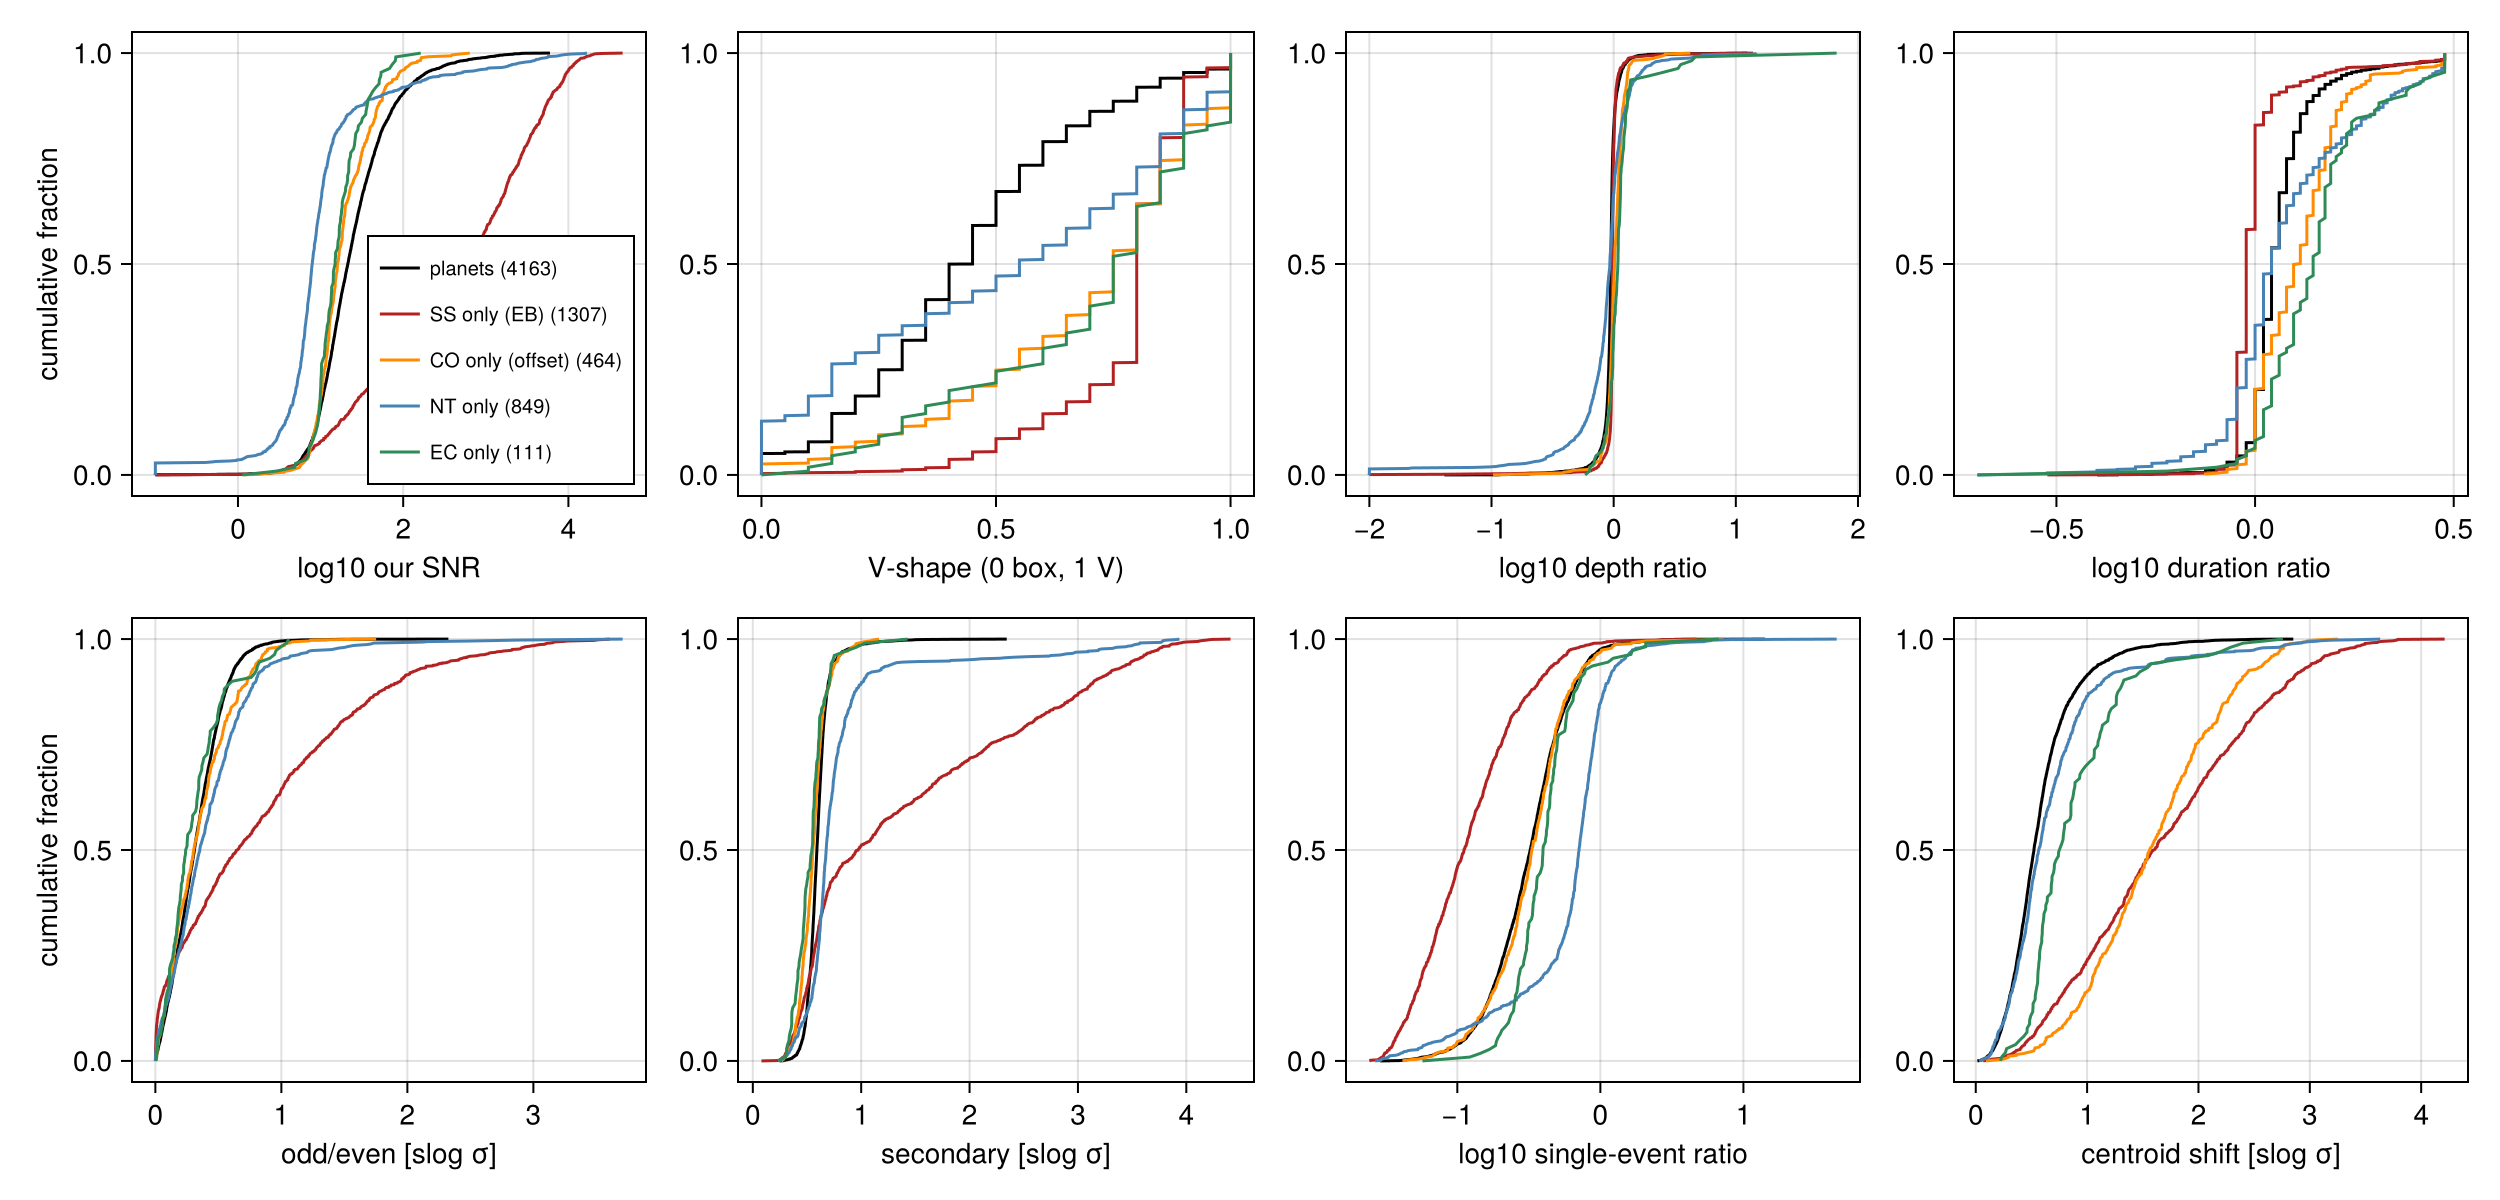

In [2]:
classes = [("planets", y .== 1), ("SS only (EB)", (y .== 0) .& (fpat .== "SS")),
           ("CO only (offset)", (y .== 0) .& (fpat .== "CO")), ("NT only", (y .== 0) .& (fpat .== "NT")),
           ("EC only", (y .== 0) .& (fpat .== "EC"))]
cols = [:black, :firebrick, :darkorange, :steelblue, :seagreen]
slog(x) = sign(x) * log10(1 + abs(x))
panels = [(:lc_snr, "log10 our SNR", x -> log10(max(x, 0.1))), (:lc_vshape, "V-shape (0 box, 1 V)", identity),
          (:lc_depth_ratio, "log10 depth ratio", x -> log10(clamp(x, 0.01, 100))),
          (:lc_dur_ratio, "log10 duration ratio", x -> log10(clamp(x, 0.01, 100))),
          (:lc_oe_sig, "odd/even [slog σ]", slog), (:lc_sec_sig, "secondary [slog σ]", slog),
          (:lc_sev_ratio, "log10 single-event ratio", x -> log10(clamp(x, 0.01, 100))),
          (:lc_cen_sig, "centroid shift [slog σ]", slog)]
fig = Figure(size = (1250, 600))
for (k, (c, lab, f)) in enumerate(panels)
    ax = Axis(fig[(k - 1) ÷ 4 + 1, (k - 1) % 4 + 1]; xlabel = lab, ylabel = (k - 1) % 4 == 0 ? "cumulative fraction" : "")
    for ((name, m), col) in zip(classes, cols)
        v = sort(f.(filter(isfinite, pool[m, c])))
        lines!(ax, v, range(0, 1; length = length(v)); color = col, label = "$name ($(sum(m)))")
    end
    k == 1 && axislegend(ax; position = :rb, labelsize = 10)
end
fig

How much does each feature separate planets from FPs **on its own**? Single-feature DR25 ROC-AUC on the pool,
folded so that 0.5 = useless and 1 = perfect in either direction (KOIs where the feature is undefined are left out).

In [3]:
uni = DataFrame(feature = String[], defined = Int[], auc_dr25 = Float64[], planets_higher = Bool[])
for c in [LC_FEATURES; LC_CENTROID_FEATURES]
    m = dr .& isfinite.(pool[!, c])
    a = fast_auc(y[m], pool[m, c])
    push!(uni, (string(c), sum(m), round(max(a, 1 - a); digits = 3), a > 0.5))
end
sort(uni, :auc_dr25; rev = true)

Row,feature,defined,auc_dr25,planets_higher
,String,Int64,Float64,Bool
1,lc_cen_sig,6989,0.862,false
2,lc_vshape,7195,0.826,false
3,lc_depth_ratio,7198,0.709,false
4,lc_sec_phase,6995,0.703,false
5,lc_ntransits,7199,0.652,false
6,lc_cen_offset,6986,0.617,false
7,lc_sec_sig,6995,0.61,false
8,lc_sev_ratio,7172,0.6,true
9,lc_dur_ratio,7195,0.585,true


- **Centroid shift** is the strongest single feature (0.86), as expected: it is what the CO flag measures, which
  is why it is kept in the "+ centroid" family only. Background EBs (CO) and EBs (SS) shift the centroid most.
- Among the flux features, **V-shape** is by far the best alone (0.83): planets are box-like, and every FP class is
  more V-shaped, EBs most of all. Next come the **depth ratio** and the **secondary's phase** (~0.70).
- Some features matter for one class only, so their single AUC understates them:
  - EBs (SS) have the highest SNR by far, plus significant secondaries and odd/even differences;
  - NT FPs have the lowest SNR and a tail of depth ratios ≪ 1: their "transit" does not survive our detrending.
    Their single-event ratio is high: one or a few events carry the signal, rather than a steady repeating transit.
    EBs sit lowest on that ratio, since many deep, equal eclipses mean no single one dominates.

  Because SNR is high for EBs and low for NT FPs, with planets in between, its single AUC is only 0.56, yet a tree
  uses it well.
- Individually none comes close to the catalog model (DR25 CV 0.955), so any gain must come from what they add
  **on top of** the catalog numbers. That is the M3 test.

## 2. M3: Phase 1 vs Phase 2a in cross-validation

Same learners as Phase 1 (rank-gauss MLP 64-32 and EvoTrees depth 8, 50/50 average, 10 seeds each), same
5 fold shuffles, so every comparison is paired. Δ = Phase 2a − Phase 1, with a paired star-bootstrap 95% CI
(`sweeps/p2_cv.jl`).

In [4]:
CSV.read(joinpath(CV_DIR, "p2_cv_summary.csv"), DataFrame)

Row,family,subset,n,phase1,phase2a,delta,ci_lo,ci_hi
,DataStri…,DataStri…,Int64,Float64,Float64,Float64,Float64,Float64
1,catalog,DR25 KOIs,7199,0.9552,0.9705,0.0153,0.0124,0.0181
2,catalog,supplemental KOIs,1089,0.6678,0.6959,0.0281,0.0039,0.055
3,catalog,all pool,8288,0.9352,0.9536,0.0184,0.0154,0.0218
4,catalog + centroid,DR25 KOIs,7199,0.983,0.9869,0.0039,0.0026,0.0052
5,catalog + centroid,supplemental KOIs,1089,0.7549,0.7661,0.0112,-0.0077,0.0311
6,catalog + centroid,all pool,8288,0.9699,0.9752,0.0053,0.0037,0.0068


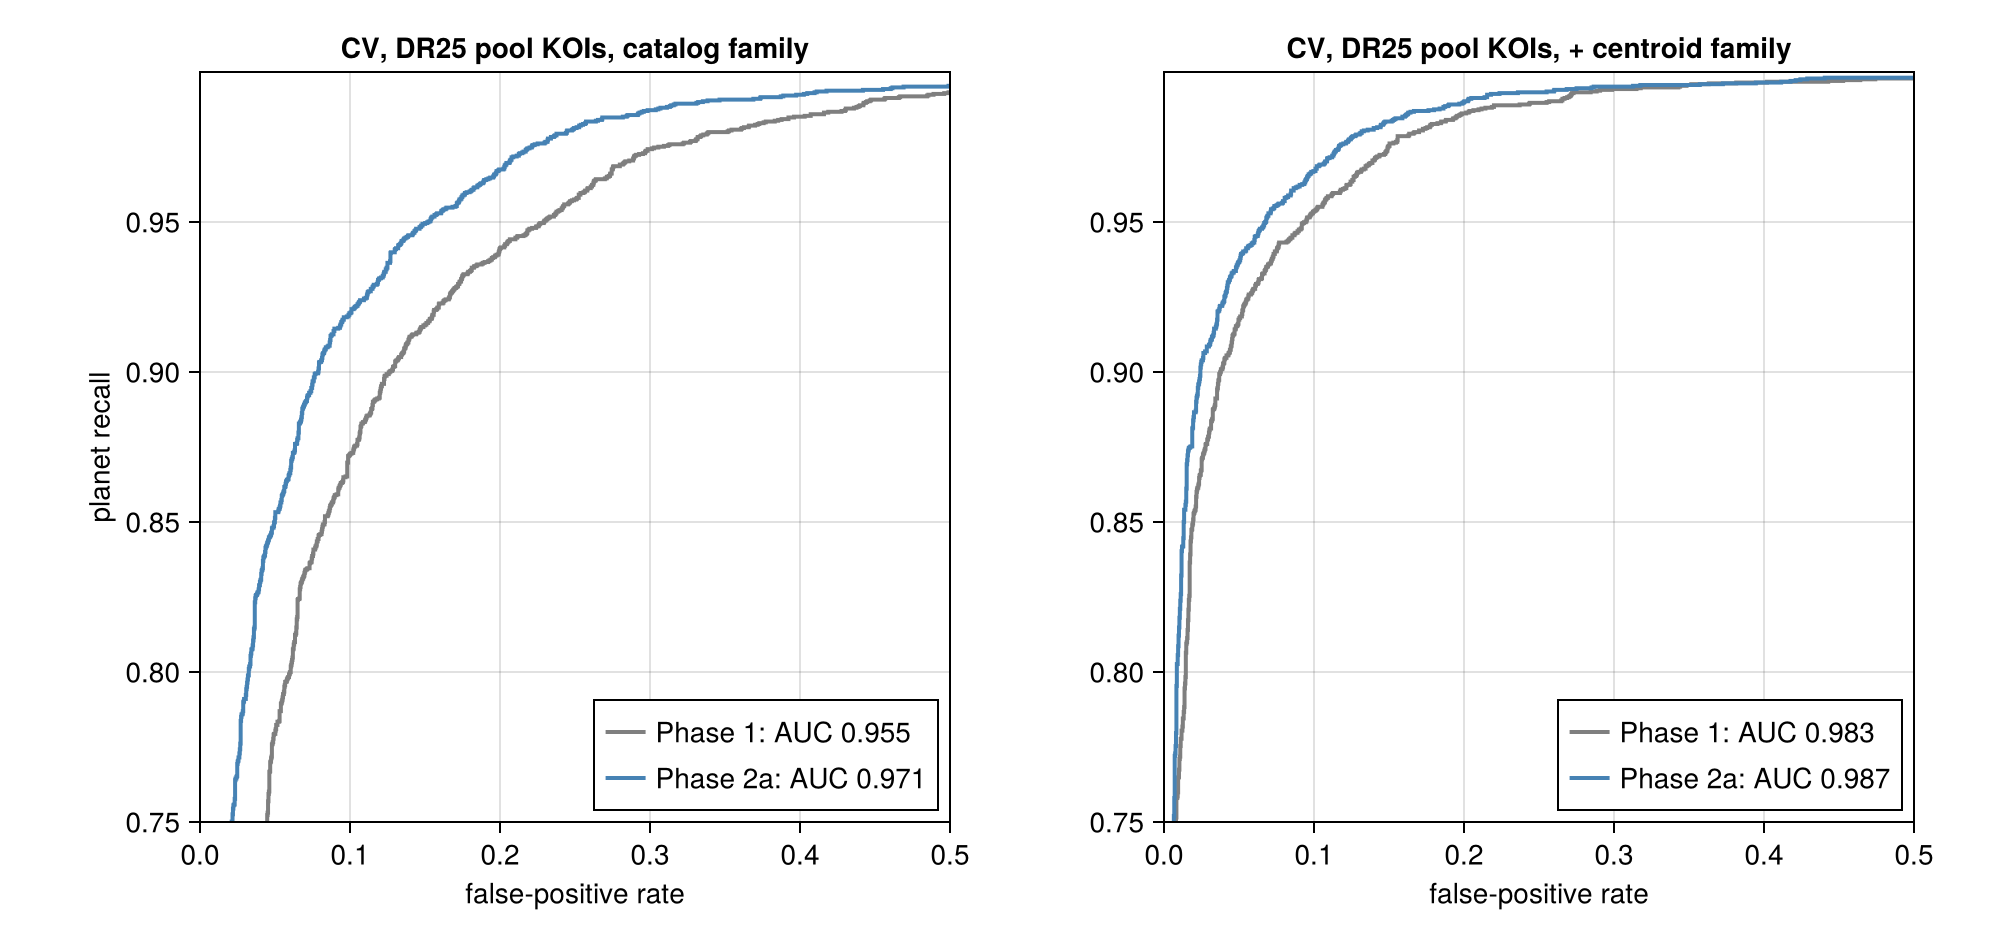

In [5]:
MODELS = [("catalog", "Phase 1", "cv_mlp_lr3_e600_quantile_r5s10.jld2", "cv_evotree_tuned_r5s10.jld2"),
          ("catalog", "Phase 2a", "cv_mlpq_lc_r5s10.jld2", "cv_evotree_lc_r5s10.jld2"),
          ("+ centroid", "Phase 1", "cv_mlpq_centroid_r5s10.jld2", "cv_evotree_centroid_r5s10.jld2"),
          ("+ centroid", "Phase 2a", "cv_mlpq_lccent_r5s10.jld2", "cv_evotree_lccent_r5s10.jld2")]
"[n_pool, repeats] seed-mean OOF score per fold shuffle of the 50/50 MLP + trees average."
function scores(fm, ft)
    a, b = load_cv(fm), load_cv(ft)
    @assert a.kepoi == pool.kepoi_name && a.folds == b.folds
    return (repeat_scores(a) .+ repeat_scores(b)) ./ 2
end
S = Dict((fam, ph) => scores(fm, ft) for (fam, ph, fm, ft) in MODELS)
fig = Figure(size = (1000, 470))
for (j, fam) in enumerate(("catalog", "+ centroid"))
    ax = Axis(fig[1, j]; title = "CV, DR25 pool KOIs, $fam family", xlabel = "false-positive rate",
              ylabel = j == 1 ? "planet recall" : "", aspect = 1, limits = (0, 0.5, 0.75, 1.0))
    for (ph, col) in (("Phase 1", :gray50), ("Phase 2a", :steelblue))
        s = vec(mean(S[(fam, ph)]; dims = 2))
        fpr, tpr = roccurve(y[dr], s[dr])
        lines!(ax, fpr, tpr; color = col, linewidth = 2, label = @sprintf("%s: AUC %.3f", ph, fast_auc(y[dr], s[dr])))
    end
    axislegend(ax; position = :rb)
end
fig

**M3 result: the light-curve features help, in both families, with CIs clear of zero.**
- Catalog family: DR25 0.955 → **0.971** (+0.015 [+0.012, +0.018]). Each learner improves alone (trees +0.017,
  MLP +0.015).
- "+ centroid" family: 0.983 → **0.987** (+0.004 [+0.003, +0.005]). Smaller, because the centroid features
  already catch much of what the light curves show (background EBs).
- Supplemental KOIs also rise (0.668 → 0.696, CI above 0, in the catalog family), but they remain hard: these
  signals sit near the detection limit, so our light-curve measurements are noisy too.
- The gain is largest at low false-positive rates in the catalog family: the curves separate most on the left.

## 3. Blind spots: which errors got smaller?

The Phase 2 plan's criterion 2: the false-positive types Phase 1 missed most (NT = not transit-like,
EC = ephemeris match / contamination) should fall below 15% missed. Nested hard calls on the CV pool, averaged over
fold shuffles, at p = 0.5 and at the 98%-recall threshold (`sweeps/p2_m5.jl --analyze`).

In [6]:
crit = CSV.read(joinpath(CV_DIR, "p2_m5_criteria.csv"), DataFrame)
wide = DataFrame(group = String[], n = Int[], family = String[], p05_phase1 = Float64[], p05_phase2a = Float64[],
                 r98_phase1 = Float64[], r98_phase2a = Float64[])
for g in unique(crit.group), fam in ("catalog", "+ centroid")
    a = crit[(crit.group .== g) .& (crit.family .== fam) .& (crit.phase .== "Phase 1"), :]
    b = crit[(crit.group .== g) .& (crit.family .== fam) .& (crit.phase .== "Phase 2a"), :]
    push!(wide, (g, a.n[1], fam, a.pct_at_p05[1], b.pct_at_p05[1], a.pct_at_recall98[1], b.pct_at_recall98[1]))
end
wide            # percent of the group called wrongly

Row,group,n,family,p05_phase1,p05_phase2a,r98_phase1,r98_phase2a
,String,Int64,String,Float64,Float64,Float64,Float64
1,FP missed: NT only,849,catalog,22.8,20.8,73.6,70.7
2,FP missed: NT only,849,+ centroid,27.0,23.7,66.6,60.2
3,FP missed: EC only,111,catalog,21.4,18.0,52.8,44.3
4,FP missed: EC only,111,+ centroid,26.3,23.2,47.2,33.7
5,FP missed: CO only,464,catalog,36.0,34.6,71.9,60.8
6,FP missed: CO only,464,+ centroid,4.0,5.3,10.8,10.9
7,FP missed: SS only,1307,catalog,3.7,3.1,14.3,9.4
8,FP missed: SS only,1307,+ centroid,6.4,5.1,12.8,9.8
9,FP missed: all,4125,catalog,15.1,12.2,42.2,33.0


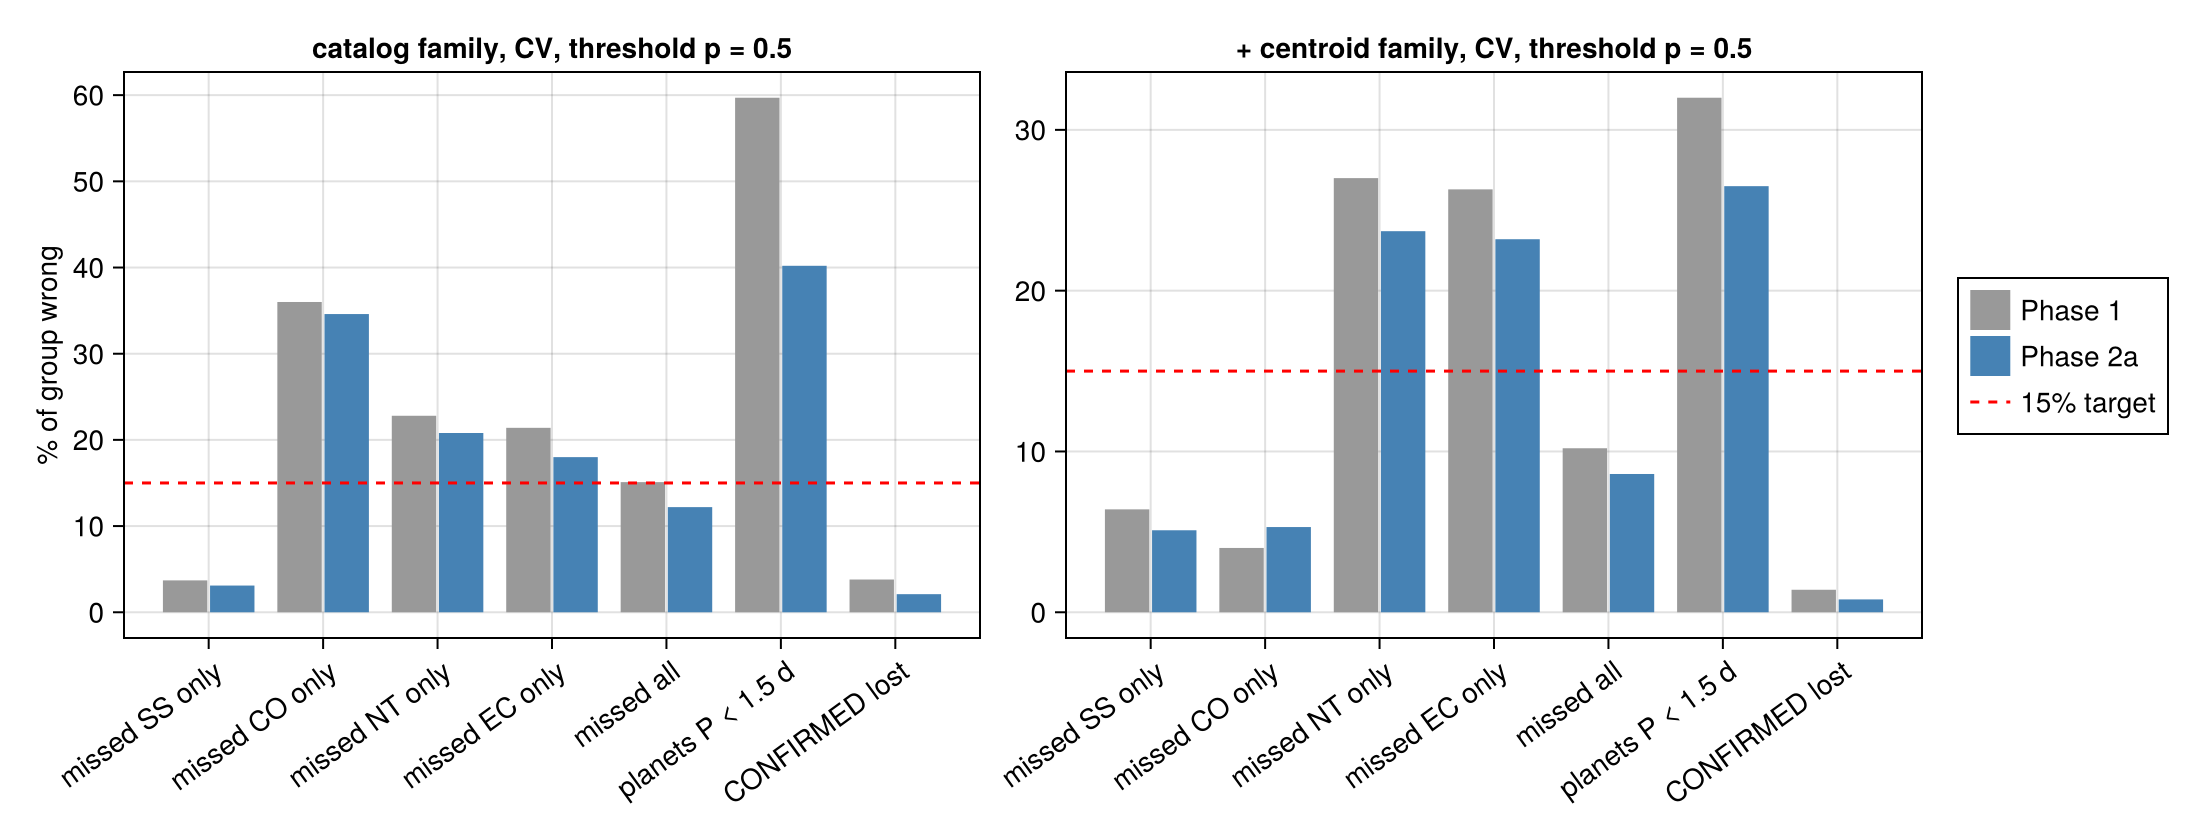

In [7]:
fig = Figure(size = (1100, 420))
gs = ["FP missed: SS only", "FP missed: CO only", "FP missed: NT only", "FP missed: EC only", "FP missed: all",
      "planet called FP: P < 1.5 d", "CONFIRMED called FP"]
for (j, fam) in enumerate(("catalog", "+ centroid"))
    w = wide[wide.family .== fam, :]
    v = [w[w.group .== g, :] for g in gs]
    ax = Axis(fig[1, j]; title = "$fam family, CV, threshold p = 0.5", ylabel = j == 1 ? "% of group wrong" : "",
              xticks = (1:length(gs), replace.(gs, "FP missed: " => "missed ", "planet called FP: " => "planets ",
                                               "CONFIRMED called FP" => "CONFIRMED lost")),
              xticklabelrotation = π / 5)
    barplot!(ax, [1:length(gs); 1:length(gs)], [[r.p05_phase1[1] for r in v]; [r.p05_phase2a[1] for r in v]];
             dodge = [fill(1, length(gs)); fill(2, length(gs))], color = [fill(:gray60, length(gs)); fill(:steelblue, length(gs))])
    hlines!(ax, [15]; color = :red, linestyle = :dash)
end
Legend(fig[1, 3], [PolyElement(color = :gray60), PolyElement(color = :steelblue),
                   LineElement(color = :red, linestyle = :dash)], ["Phase 1", "Phase 2a", "15% target"])
fig

- **Every FP group shrinks**, except CO-only in the "+ centroid" family, which is already low (4.0 → 5.3% at
  p = 0.5; unchanged at 98% recall). Planets lost do not rise: CONFIRMED planets called FP fall from 3.8% to
  2.1% (catalog) and from 1.4% to 0.8% (+ centroid) at p = 0.5.
- **Ultra-short-period planets** (P < 1.5 d), which Phase 1 wrongly rejected 60% of the time in the catalog family
  (they look like EBs in catalog numbers), fall to **40%**. The light curves show they are U-shaped and without
  secondaries.
- **NT and EC remain the blind spots** (criterion 2 only partly met): NT 22.8 → 20.8% / 27.0 → 23.7%,
  EC 21.4 → 18.0% / 26.3 → 23.2%, still above the 15% target.
  - NT FPs are mostly stellar variability and systematics that *do* fold into a transit-like dip after detrending,
    so the per-KOI features see a plausible transit.
  - EC FPs are contamination by another star's signal (ephemeris match, often by direct PRF overlap or CCD
    cross-talk). Telling them apart needs **other stars' ephemerides**, which no per-KOI feature here contains.
    This is the clearest direction for further work.

## 4. M4, Phase 2b: a CNN on the views (tried, not used)

A small AstroNet-style two-tower 1D CNN (~180k parameters, CPU-trained; `src/CNN.jl`, `sweeps/p2_cnn.jl`) on the
local, odd, even and secondary views, optionally joined with the tabular features and the centroid views. The gate
was: beat Phase 2a, or improve it in a 50/50 ensemble. Screens use 1 fold shuffle × 2 seeds; the most promising
variant (`hybrid_lc`) also ran the full 5 × 3. Here: DR25 pool AUC on the same folds, without bootstrap
(the paired CIs are in `sweeps/results/p2_cnn.log` and STATUS).

In [8]:
CNNS = [("views only", "views", 1), ("+ catalog", "hybrid", 1), ("+ catalog + LC", "hybrid_lc", 1),
        ("+ catalog + LC (final 5×3)", "hybrid_lc", 5), ("centroid views + catalog + centroid", "cent", 1),
        ("centroid views + all", "cent_lc", 1)]
cnn = DataFrame(variant = String[], run = String[], cnn_alone = Float64[], phase2a = Float64[], delta = Float64[],
                ensemble_5050 = Float64[], ensemble_delta = Float64[])
for (lab, v, R) in CNNS
    cv = load_cv("cv_cnn_$(v)_r$(R)s$(R == 1 ? 2 : 3).jld2")
    @assert cv.kepoi == pool.kepoi_name
    fam = startswith(v, "cent") ? "+ centroid" : "catalog"
    c = vec(mean(cv.oof; dims = (2, 3)))
    b = vec(mean(S[(fam, "Phase 2a")][:, 1:R]; dims = 2))
    e = (c .+ b) ./ 2
    A(s) = round(fast_auc(y[dr], s[dr]); digits = 4)
    push!(cnn, (lab, R == 1 ? "screen 1×2" : "final 5×3", A(c), A(b), round(A(c) - A(b); digits = 4), A(e),
                round(A(e) - A(b); digits = 4)))
end
cnn

Row,variant,run,cnn_alone,phase2a,delta,ensemble_5050,ensemble_delta
,String,String,Float64,Float64,Float64,Float64,Float64
1,views only,screen 1×2,0.9493,0.9694,-0.0201,0.9672,-0.0022
2,+ catalog,screen 1×2,0.958,0.9694,-0.0114,0.9685,-0.0009
3,+ catalog + LC,screen 1×2,0.9623,0.9694,-0.0071,0.9686,-0.0008
4,+ catalog + LC (final 5×3),final 5×3,0.9638,0.9705,-0.0067,0.9694,-0.0011
5,centroid views + catalog + centroid,screen 1×2,0.9798,0.9865,-0.0067,0.9855,-0.001
6,centroid views + all,screen 1×2,0.9825,0.9865,-0.004,0.9858,-0.0007


- **The views carry real signal:** the CNN on the views alone reaches 0.949, about Phase 1's catalog level, from
  the folded flux curves alone.
- **But every variant is below Phase 2a**, by 0.004–0.020, and **none adds to it**: the 50/50 ensembles are
  0.001–0.002 lower (paired CIs at or below 0). The final 5 × 3 run of the best catalog-family variant confirms the
  screen (0.964 vs 0.971).
- The 11 hand-made features already capture what a small CNN learns from ~8,000 training KOIs. A larger network,
  augmentation, or GPU-scale training might change that, but on this CPU each 5 × 3 run takes ~6.4 h, so M4 was
  stopped by decision and **Phase 2a became the Phase 2 model**.

## 5. M5: calibration and the operating-point menu

Same procedure as Phase 1 step 5 (`src/Calibration.jl`): nested calibration (fit on the other folds) and nested
thresholds chosen on DR25 KOIs.

In [9]:
cal = CSV.read(joinpath(CV_DIR, "p2_m5_calibration.csv"), DataFrame)
cal[cal.subset .!= "all", :]

Row,family,calibrator,subset,logloss,brier,ece,roc_auc,mean_p,planet_rate
,DataStri…,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Float64,Float64
1,catalog,none,DR25,0.2226,0.0664,0.0118,0.9698,0.516,0.513
2,catalog,none,supplemental,0.6342,0.2194,0.0615,0.6916,0.418,0.431
3,catalog,platt,DR25,0.2226,0.0664,0.0099,0.9697,0.515,0.513
4,catalog,platt,supplemental,0.6376,0.2202,0.0637,0.6911,0.415,0.431
5,catalog,isotonic,DR25,0.2255,0.0666,0.0081,0.9691,0.516,0.513
6,catalog,isotonic,supplemental,0.6424,0.2205,0.0663,0.6862,0.411,0.431
7,+ centroid,none,DR25,0.1472,0.0426,0.0119,0.9865,0.517,0.513
8,+ centroid,none,supplemental,0.5674,0.1953,0.0529,0.7617,0.405,0.431
9,+ centroid,platt,DR25,0.1473,0.0427,0.0103,0.9864,0.517,0.513


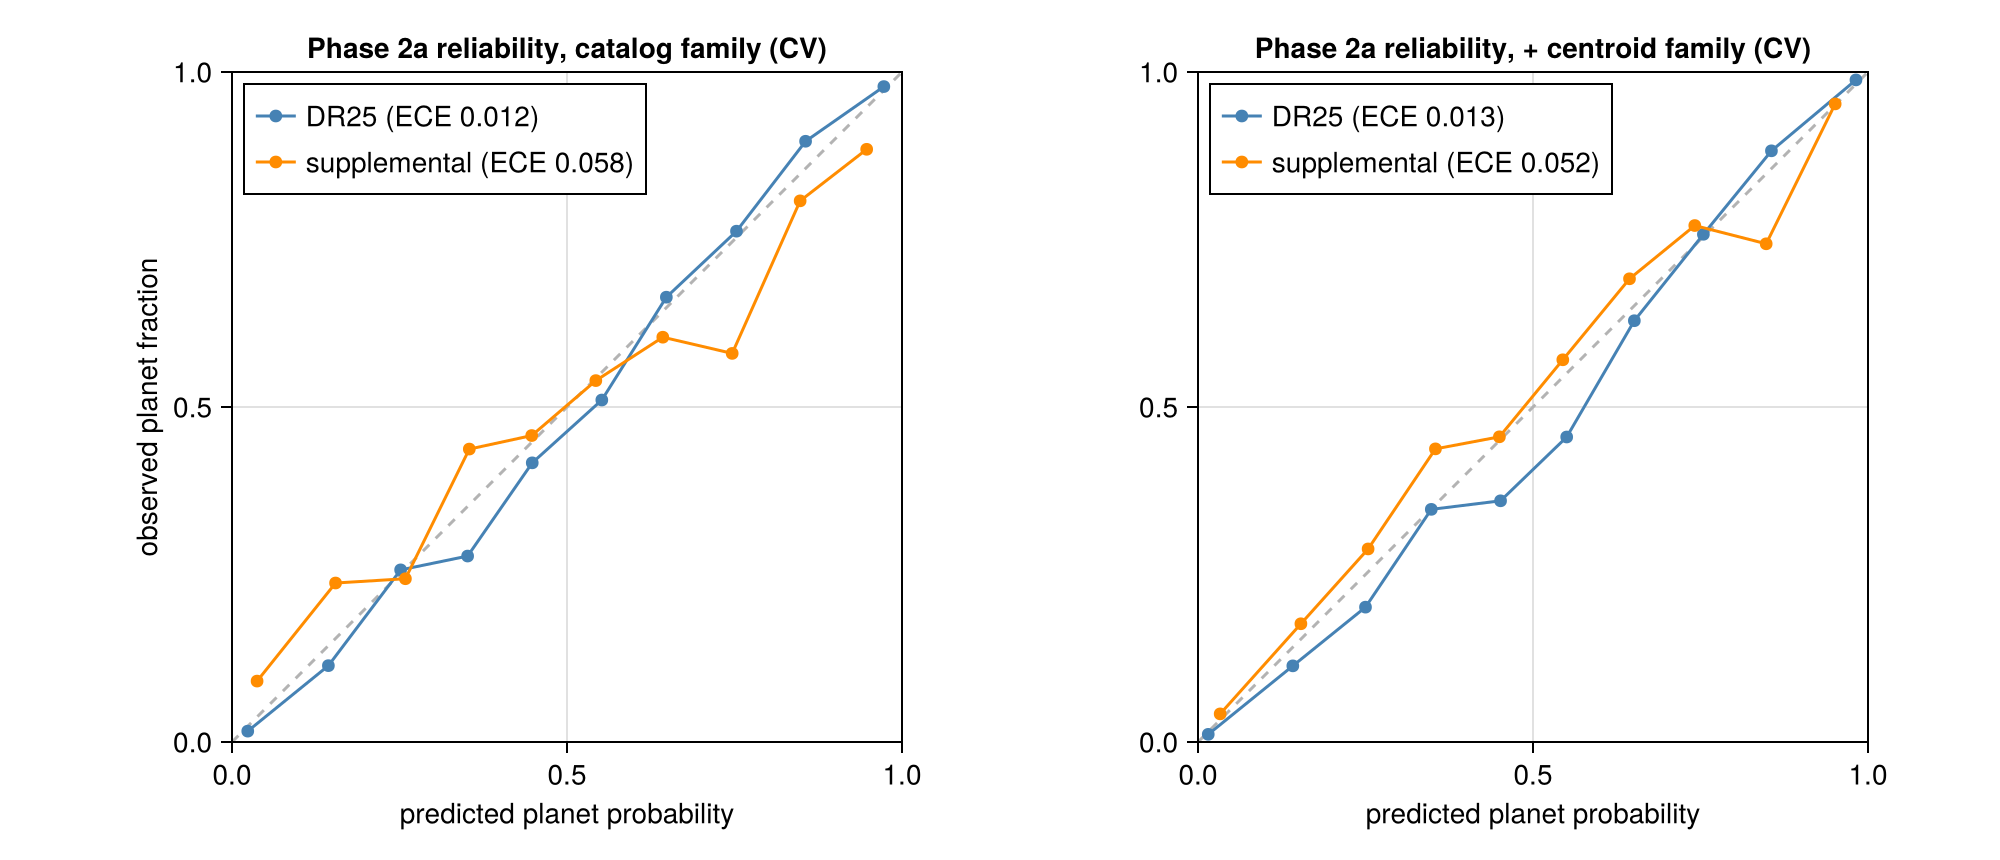

In [10]:
fig = Figure(size = (1000, 430))
for (j, fam) in enumerate(("catalog", "+ centroid"))
    ax = Axis(fig[1, j]; title = "Phase 2a reliability, $fam family (CV)", xlabel = "predicted planet probability",
              ylabel = j == 1 ? "observed planet fraction" : "", aspect = 1, limits = (0, 1, 0, 1))
    lines!(ax, [0, 1], [0, 1]; color = :gray70, linestyle = :dash)
    s = vec(mean(S[(fam, "Phase 2a")]; dims = 2))
    for (lab, m, col) in (("DR25", dr, :steelblue), ("supplemental", .!dr, :darkorange))
        bx, by = Float64[], Float64[]
        for i in 1:10
            k = m .& (clamp.(floor.(Int, 10 .* s) .+ 1, 1, 10) .== i)
            sum(k) >= 10 && (push!(bx, mean(s[k])); push!(by, mean(y[k])))
        end
        scatterlines!(ax, bx, by; color = col, label = @sprintf("%s (ECE %.3f)", lab, ece(y[m], s[m])))
    end
    axislegend(ax; position = :lt)
end
fig

**No calibration is needed.** A Platt fit on all out-of-fold scores gives a = 1.04, b ≈ 0 (1, 0 = already
calibrated), and nested Platt or isotonic do not lower DR25 log-loss. On DR25 KOIs the scores read as planet
probabilities (ECE 0.012–0.013). Supplemental KOIs are less well calibrated (ECE 0.05–0.06), as in Phase 1. In the
catalog family their high scores are over-confident (a score of 0.75 means ~58% planets). Their signals sit near
the detection limit, unlike the DR25 KOIs that dominate training.

The **operating-point menu** (nested on CV, DR25 KOIs). The headline rule, fixed before the test, is 98% planet
recall: keep 98% of planets and see how many false positives survive.

In [11]:
ops = CSV.read(joinpath(CV_DIR, "p2_m5_operating_points.csv"), DataFrame)
ops[:, [:family, :phase, :rule, :t_median, :dr25_recall, :dr25_precision, :dr25_fp_kept, :fps_kept_per1000,
        :confirmed_lost]]

Row,family,phase,rule,t_median,dr25_recall,dr25_precision,dr25_fp_kept,fps_kept_per1000,confirmed_lost
,DataStri…,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Int64,Float64
1,catalog,Phase 1,planet recall 95%,0.312,0.95,0.814,0.229,111,0.015
2,catalog,Phase 1,planet recall 98%,0.147,0.98,0.745,0.353,172,0.004
3,catalog,Phase 1,planet recall 99%,0.075,0.99,0.696,0.456,222,0.002
4,catalog,Phase 1,precision 95%,0.775,0.741,0.949,0.042,20,0.134
5,catalog,Phase 1,precision 99%,0.979,0.289,0.987,0.004,2,0.593
6,catalog,Phase 1,max F1,0.491,0.904,0.874,0.137,67,0.036
7,catalog,Phase 1,p = 0.5,0.5,0.9,0.881,0.129,63,0.038
8,catalog,Phase 2a,planet recall 95%,0.358,0.949,0.865,0.156,76,0.011
9,catalog,Phase 2a,planet recall 98%,0.178,0.98,0.805,0.251,122,0.004


At 98% recall, Phase 2a keeps **25%** of DR25 false positives in the catalog family (Phase 1: 35%) and **14%**
with centroids (17%), with the same 0.3–0.4% of CONFIRMED planets lost. Per 1,000 DR25 KOIs that is 122 instead
of 172 false positives passed on (catalog), and 67 instead of 84 (+ centroid).

**Freeze** (`sweeps/p2_m5.jl --freeze`, `models/p2_frozen.jld2`): both Phase 2a models retrained on the whole pool
(10 MLP + 10 tree seeds, the same inner early-stopping split as Phase 1), with the menu's median thresholds
(98% recall: catalog 0.185, + centroid 0.244) and no calibrator.

## 6. M6: the sealed test (scored once)

The frozen models were scored **once** on the same sealed test split as Phase 1 (`split_by_star` seed 42; 913 KOIs
on 792 stars, never used for training, tuning or model choice) by `sweeps/p2_test.jl`, which refuses to score again.
Everything below reads its saved predictions. Headline: the 796 DR25 KOIs, 95% star-bootstrap CIs, and the paired
Δ vs Phase 1's test predictions on the same KOIs.

In [12]:
tauc = CSV.read(joinpath(CV_DIR, "p2_test_auc.csv"), DataFrame)
tauc

Row,model,subset,n,test_auc,test_ci,cv_expected,phase1_test_auc,delta_vs_phase1
,DataStri…,DataStri…,Int64,Float64,DataStri…,Float64,Float64,DataStri…
1,catalog-only,DR25 KOIs (headline),796,0.9756,"[0.966, 0.984]",0.9698,0.9573,"+0.0182 [+0.0108, +0.0267]"
2,catalog-only,DR25 CONFIRMED vs FP,661,0.9891,"[0.983, 0.994]",0.9887,0.9745,"+0.0146 [+0.0081, +0.0221]"
3,catalog-only,supplemental KOIs,117,0.76,"[0.672, 0.846]",0.6916,0.7242,"+0.0358 [-0.0373, +0.1103]"
4,catalog-only,all KOIs,913,0.9626,"[0.952, 0.972]",0.9527,0.9413,"+0.0212 [+0.0134, +0.0306]"
5,catalog + centroid,DR25 KOIs (headline),796,0.9927,"[0.988, 0.996]",0.9865,0.9883,"+0.0043 [+0.0010, +0.0086]"
6,catalog + centroid,DR25 CONFIRMED vs FP,661,0.9975,"[0.995, 1.000]",0.9966,0.9954,"+0.0021 [-0.0004, +0.0051]"
7,catalog + centroid,supplemental KOIs,117,0.7973,"[0.713, 0.871]",0.7617,0.7875,"+0.0099 [-0.0499, +0.0735]"
8,catalog + centroid,all KOIs,913,0.9829,"[0.977, 0.989]",0.9746,0.9786,"+0.0044 [+0.0004, +0.0088]"
9,robovetter koi_score (reference),DR25 KOIs (headline),796,0.9794,—,NaN,NaN,—


In [13]:
tops = CSV.read(joinpath(CV_DIR, "p2_test_operating_points.csv"), DataFrame)
tops[in.(tops.rule, Ref(["planet recall 95%", "planet recall 98%", "planet recall 99%", "precision 95%"])),
     [:model, :rule, :t, :recall, :cv_recall, :precision, :cv_precision, :fp_kept, :cv_fp_kept, :confirmed_lost,
      :phase1_precision, :phase1_fp_kept]]

Row,model,rule,t,recall,cv_recall,precision,cv_precision,fp_kept,cv_fp_kept,confirmed_lost,phase1_precision,phase1_fp_kept
,DataStri…,DataStri…,Float64,DataStri…,Float64,DataStri…,Float64,Float64,Float64,Float64,Float64,Float64
1,catalog-only,planet recall 95%,0.359,"0.970 [0.952, 0.986]",0.949,"0.876 [0.840, 0.906]",0.865,0.144,0.156,0.007,0.832,0.2
2,catalog-only,planet recall 98%,0.185,"0.985 [0.972, 0.995]",0.98,"0.815 [0.777, 0.849]",0.805,0.233,0.251,0.004,0.771,0.305
3,catalog-only,planet recall 99%,0.082,"0.995 [0.987, 1.000]",0.99,"0.751 [0.710, 0.788]",0.752,0.344,0.344,0.0,0.715,0.413
4,catalog-only,precision 95%,0.72,"0.837 [0.799, 0.876]",0.838,"0.955 [0.933, 0.975]",0.95,0.041,0.046,0.055,0.948,0.041
5,catalog + centroid,planet recall 95%,0.487,"0.968 [0.950, 0.985]",0.949,"0.945 [0.922, 0.966]",0.935,0.059,0.069,0.011,0.934,0.072
6,catalog + centroid,planet recall 98%,0.244,"0.990 [0.979, 0.998]",0.979,"0.897 [0.868, 0.924]",0.882,0.118,0.138,0.0,0.869,0.156
7,catalog + centroid,planet recall 99%,0.107,"0.998 [0.992, 1.000]",0.99,"0.846 [0.812, 0.878]",0.838,0.19,0.202,0.0,0.827,0.218
8,catalog + centroid,precision 95%,0.562,"0.958 [0.938, 0.976]",0.937,"0.960 [0.941, 0.977]",0.95,0.041,0.052,0.011,0.953,0.049


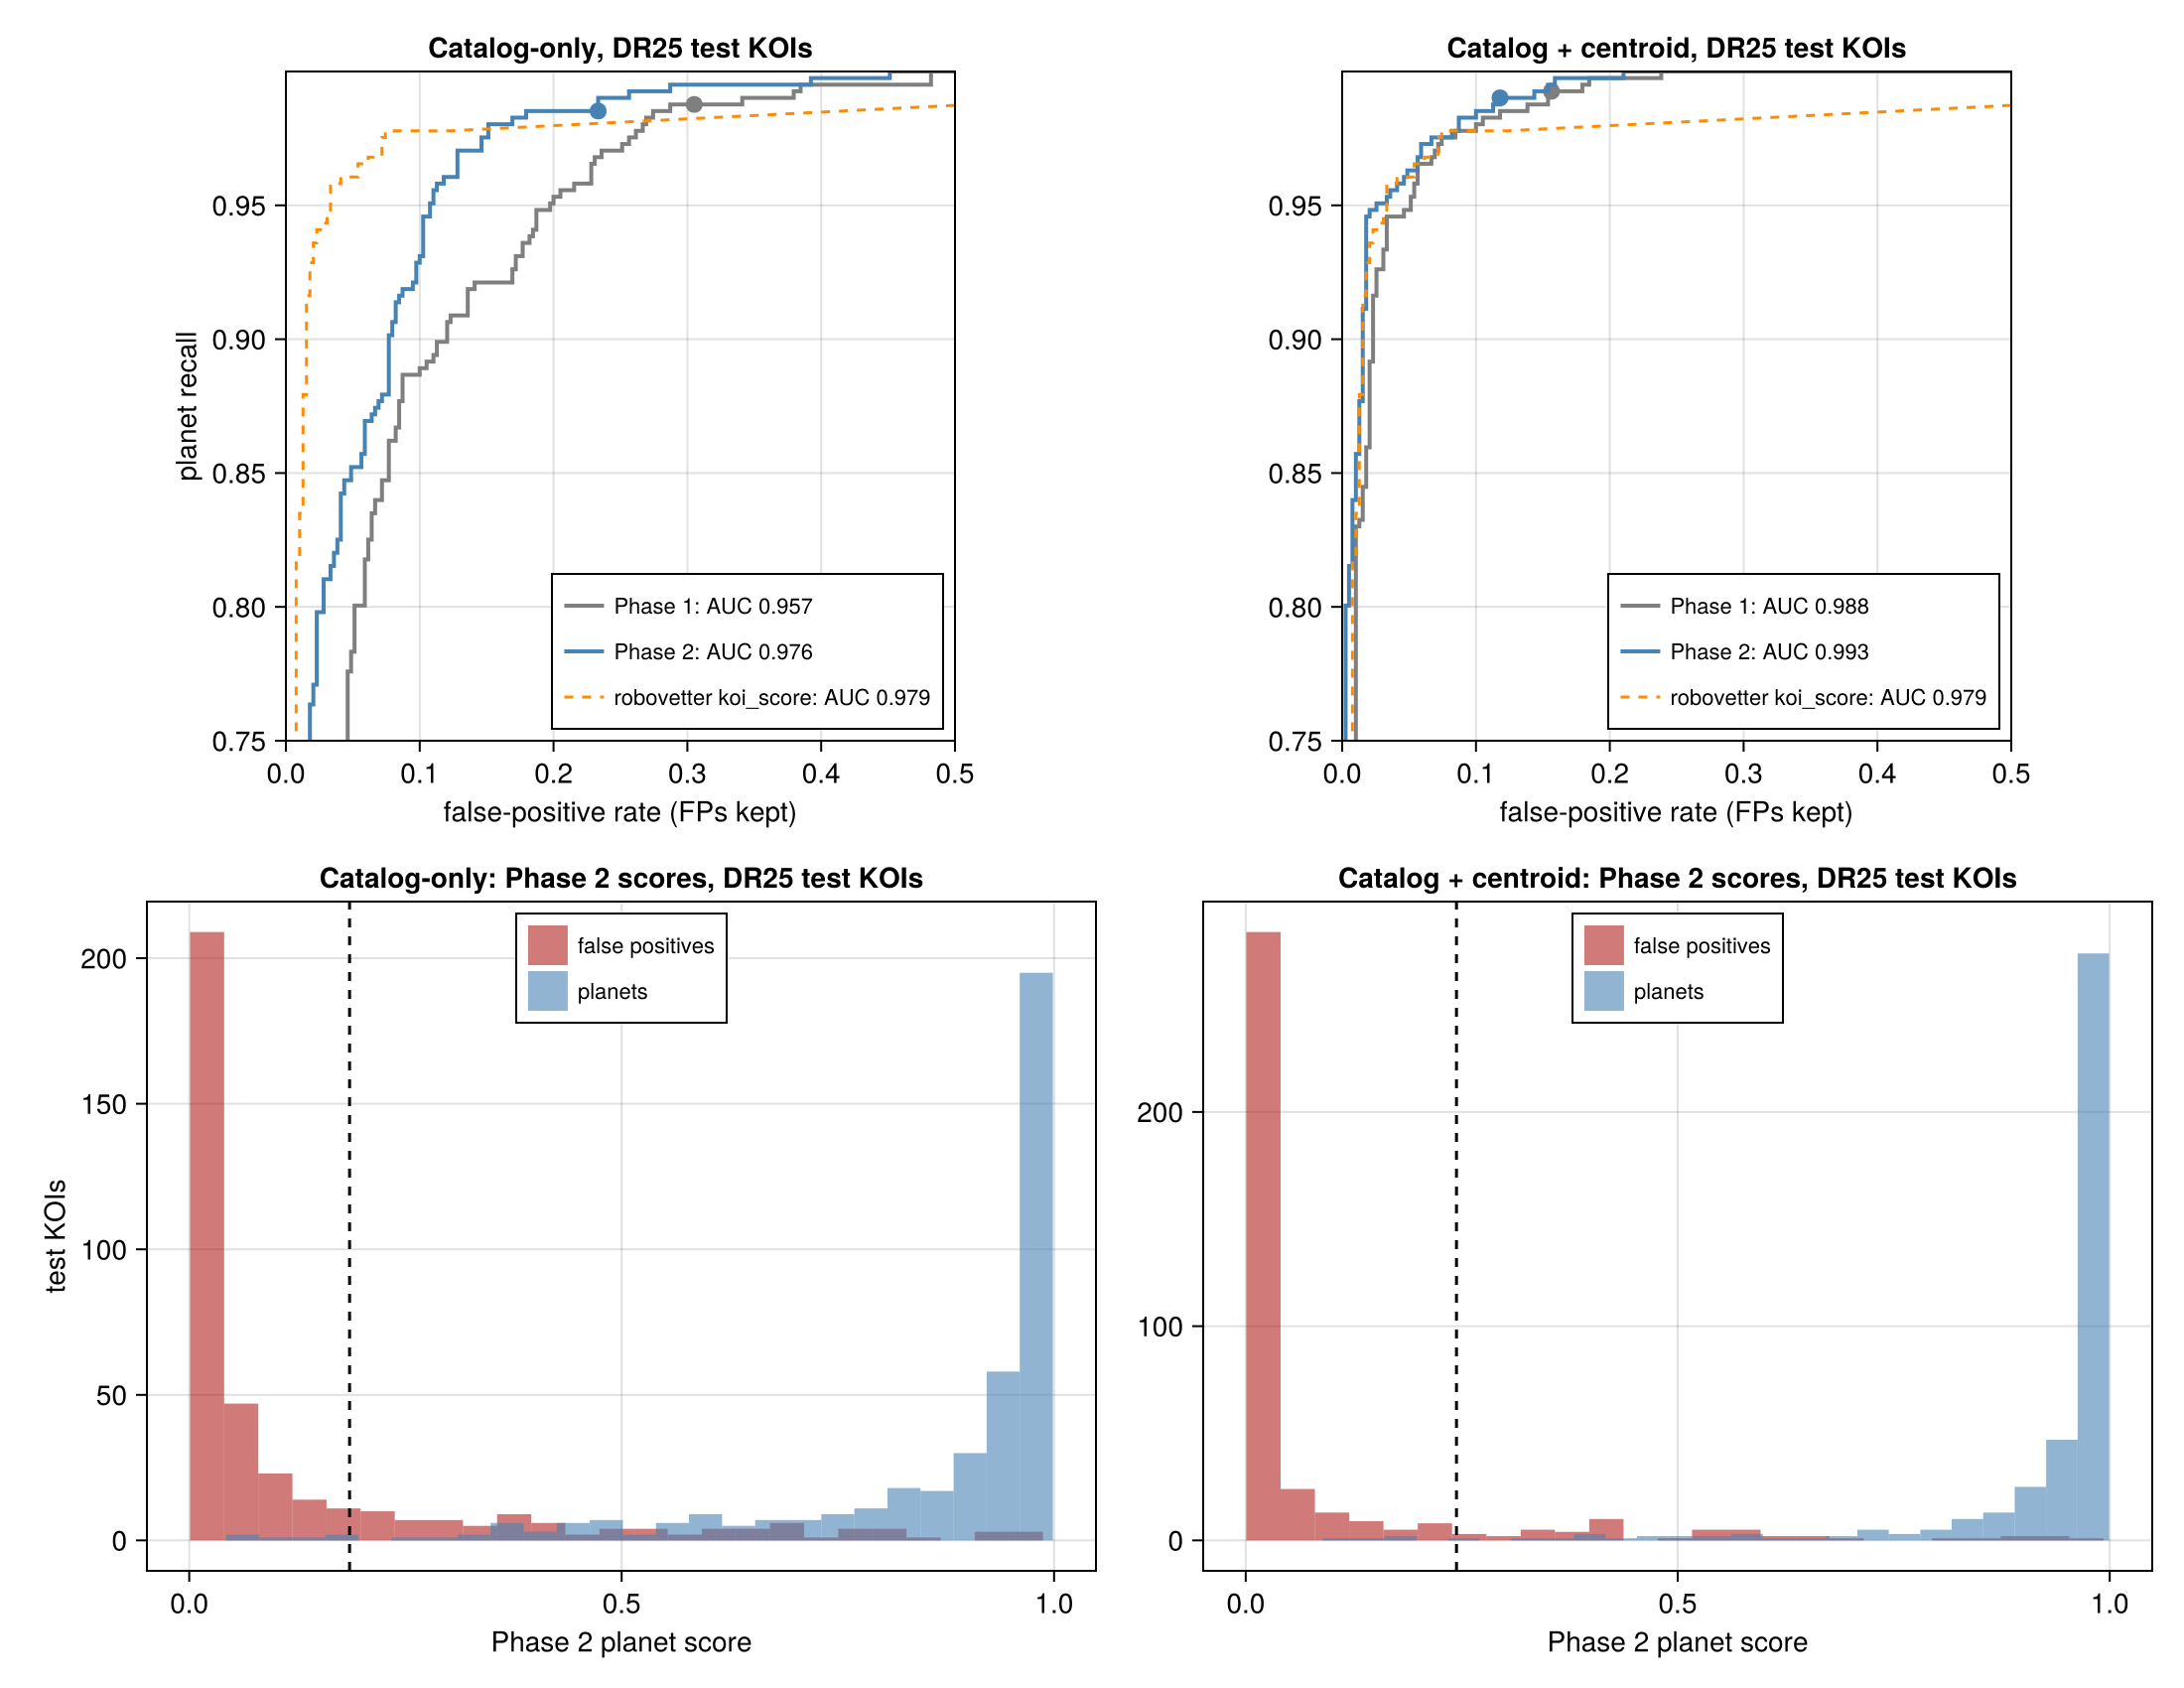

In [14]:
p2 = CSV.read(joinpath(CV_DIR, "p2_test_predictions.csv"), DataFrame)
p1 = CSV.read(joinpath(CV_DIR, "test_predictions.csv"), DataFrame)
@assert p1.kepoi_name == p2.kepoi_name
f1, f2 = Base.CoreLogging.with_logger(Base.CoreLogging.NullLogger()) do     # (only the thresholds are needed; silences JLD2's type warnings)
    [JLD2.load(joinpath(PROJECT_DIR, "models", f))["frozen"] for f in ("step5_frozen.jld2", "p2_frozen.jld2")]
end
drt = Bool.(p2.dr25)
yt = Float64.(p2.label[drt])
fig = Figure(size = (1100, 850))
for (j, (ttl, key, a, b)) in enumerate((("Catalog-only", "catalog_only", p1.p_catalog, p2.p_catalog),
                                        ("Catalog + centroid", "catalog_centroid", p1.p_centroid, p2.p_centroid)))
    ax = Axis(fig[1, j]; xlabel = "false-positive rate (FPs kept)", ylabel = j == 1 ? "planet recall" : "",
              title = "$ttl, DR25 test KOIs", aspect = 1, limits = (0, 0.5, 0.75, 1.0))
    for (lab, p, f, col) in (("Phase 1", a, f1, :gray50), ("Phase 2", b, f2, :steelblue))
        fpr, tpr = roccurve(yt, p[drt])
        lines!(ax, fpr, tpr; color = col, linewidth = 2, label = @sprintf("%s: AUC %.3f", lab, fast_auc(yt, p[drt])))
        o = op_metrics(yt, p[drt], f[key]["thresholds"]["(:recall, 0.98)"])
        scatter!(ax, [o.fp_kept], [o.recall]; color = col, markersize = 12)
    end
    ks = isfinite.(p1.koi_score[drt])
    fpr, tpr = roccurve(yt[ks], p1.koi_score[drt][ks])
    lines!(ax, fpr, tpr; color = :darkorange, linestyle = :dash,
           label = @sprintf("robovetter koi_score: AUC %.3f", fast_auc(yt[ks], p1.koi_score[drt][ks])))
    axislegend(ax; position = :rb, labelsize = 11)
    # score distributions by class, with the frozen 98%-recall threshold
    ax2 = Axis(fig[2, j]; xlabel = "Phase 2 planet score", ylabel = j == 1 ? "test KOIs" : "",
               title = "$ttl: Phase 2 scores, DR25 test KOIs")
    hist!(ax2, b[drt][yt .== 0]; bins = 25, color = (:firebrick, 0.6), label = "false positives")
    hist!(ax2, b[drt][yt .== 1]; bins = 25, color = (:steelblue, 0.6), label = "planets")
    vlines!(ax2, [f2[key]["thresholds"]["(:recall, 0.98)"]]; color = :black, linestyle = :dash)
    axislegend(ax2; position = :ct, labelsize = 11)
end
fig

Dots on the ROC curves and the dashed line in the histograms: each model's frozen 98%-recall threshold, fixed on CV.

**The sealed test confirms cross-validation.**
- **Catalog-only: 0.976** [0.966, 0.984] vs Phase 1's 0.957, paired Δ **+0.018** [+0.011, +0.027]. That is close
  to the robovetter's `koi_score` (0.979), using only catalog numbers and our own light-curve measurements. The
  robovetter is still clearly better at false-positive rates below ~15%, and ours is better above. With
  centroids, Phase 2 matches the robovetter at low FP rates and beats it above.
- **Catalog + centroid: 0.993** [0.988, 0.996] vs 0.988, paired Δ **+0.004** [+0.001, +0.009].
- **At the frozen 98%-recall threshold:** recall 0.985 / 0.990 as intended. Precision rises to 0.815 / 0.897
  (Phase 1 test: 0.771 / 0.869), and the share of false positives kept falls to **23% / 12%** (Phase 1: 31% / 16%).
  0.4% / 0% of test CONFIRMED planets are lost.
- Every CV expectation (0.970 / 0.987, the operating-point rates) lies inside its test interval. As in Phase 1, the
  test split scores slightly higher than CV, consistent with sampling (796 KOIs).
- **Supplemental KOIs** (117 in the test): 0.760 / 0.797 (Phase 1: 0.724 / 0.788). The direction matches CV, but the
  test is too small to call it.

## 7. Phase 2 conclusions

| Plan §1 criterion | Result |
|---|---|
| 1. Main: beat Phase 1 with a paired CI above 0 | **Met** in both families (CV and test) |
| 2. Blind spots: NT and EC FPs missed < 15%, supplemental AUC up | **Partly:** both fall but stay at 18–24%; supplemental up |
| 3. No regressions (CONFIRMED lost at 98% recall) | **Met:** 0.4 → 0.4% / 0.4 → 0.3% (CV) |
| 4. Stretch: catalog-only reaches `koi_score` | **Met:** CV 0.970 vs 0.970; test 0.976 vs 0.979 |

- **What worked:** a full, reproducible light-curve pipeline (53 GB from MAST → 14 GB cache → detrending, views,
  QA) and 11 noise-normalised, hand-made features. They lift the catalog model to the robovetter's level and cut the
  false positives passed on at 98% recall by about a quarter.
- **What didn't:** a small CPU-trained CNN on the views learns real signal but adds nothing beyond the features.
- **Still hard:**
  - not-transit-like (variability, systematics) and contamination FPs;
  - supplemental KOIs near the detection limit, which are also over-confident.

  The next lever for contamination is cross-KOI information: period/epoch matches against other stars' KOIs and
  eclipsing binaries, which is the information Kepler's EC flag itself uses.
- **Bookkeeping:** the sealed test set has now been scored twice in total (once per phase) and is spent for model
  choice. Any Phase 3 comparison should rest on cross-validation, or on a fresh hold-out.